# Introduction to numerical algorithms
## Practice class 7 - Numerical derivative and integration

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm
import scipy

## Numerical derivation

### Task 1: Derivatives with central finite differences

If we only know the values $y_i=f(x_i)$ on an equidistant grid $x_i=a+ih$, we can estimate the derivative from Taylor expansions around $x_i$:
$$f(x+h)=f+hf'+\tfrac{h^2}{2}f''+\tfrac{h^3}{6}f^{(3)}+\dots,\qquad f(x-h)=f-hf'+\tfrac{h^2}{2}f''-\tfrac{h^3}{6}f^{(3)}+\dots$$
Subtracting the two, the even terms cancel and we get the central difference
$$f'(x_i)\approx\frac{y_{i+1}-y_{i-1}}{2h},\qquad\text{error }O(h^2).$$
Using two neighbours on each side we can also cancel the $h^3$ term, which gives a fourth order formula
$$f'(x_i)\approx\frac{y_{i-2}-8y_{i-1}+8y_{i+1}-y_{i+2}}{12h},\qquad\text{error }O(h^4).$$

Write a function `my_der_calc(f, a, b, N, order)` where

- `f` is a function that accepts arrays, `a < b` are the interval ends, `N >= 10` is the number of grid points,
- `order` is 2 or 4 and selects the formula above,
- the grid is `x = np.linspace(a, b, N)`, `y = f(x)`, `h = x[1] - x[0]`,
- the output is `[df, X]`: the derivative and the grid points `X` where it is defined.

Near the ends of the interval the formula would need points outside the grid, so these points are lost: one point at each end for order 2, two points at each end for order 4. Use array slicing instead of loops (for order 2, `y[1:]` contains the values $y_{i+1}$ and `y[:-2]` contains the values $y_{i-1}$).

In [2]:
def my_der_calc(f, a, b, N, order=2):
    """
    First derivative of f on [a, b] with N equidistant points, central differences.
    order : 2 or 4 (order of the error O(h^order))
    Returns [df, X]: derivative values and the grid points where they are defined.
    """
    # input checks (given)
    if not callable(f):
        raise TypeError("f must be callable")
    a, b, N = float(a), float(b), int(N)
    if not a < b:
        raise ValueError("a must be smaller than b")
    if N < 10:
        raise ValueError("N must be at least 10")
    if order not in (2, 4):
        raise ValueError("order must be 2 or 4")

    x = np.linspace(a, b, N)
    y = f(x)
    h = x[1] - x[0]

    # Work here
    if order == 2:
        df = df = (y[2:] - y[:-2]) / (2 * h)
        X = x[1:-1]
    else:
        df = (y[:-4] - 8 * y[1:-3] + 8 * y[3:-1] - y[4:]) / (12 * h)
        X = x[2:-2]
    return [df, X]

### Testing

Compare with the analytic derivative (given). First $\sin x$ on a coarse grid, then a function that oscillates faster and faster and therefore needs a finer grid.

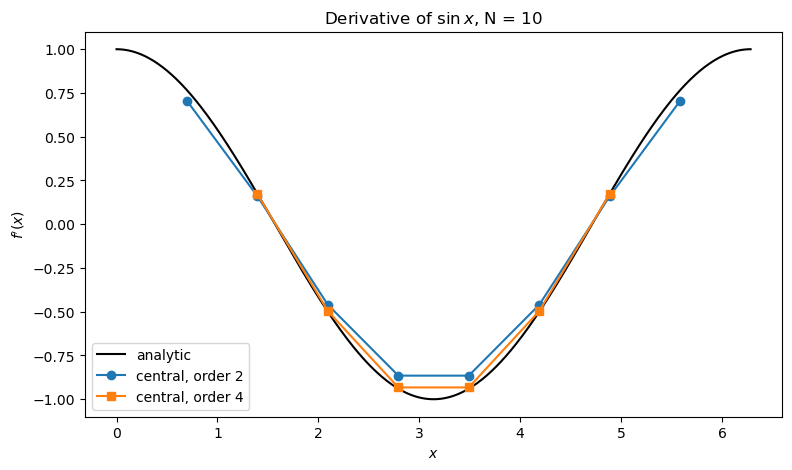

In [3]:
# Test 1: sin(x) on a coarse grid
xx = np.linspace(0, 2*np.pi, 400)
dy2, X2 = my_der_calc(np.sin, 0., 2*np.pi, 10, 2)
dy4, X4 = my_der_calc(np.sin, 0., 2*np.pi, 10, 4)

plt.figure(figsize=(9, 5))
plt.plot(xx, np.cos(xx), 'k', label='analytic')
plt.plot(X2, dy2, 'o-', label='central, order 2')
plt.plot(X4, dy4, 's-', label='central, order 4')
plt.legend(); plt.xlabel('$x$'); plt.ylabel("$f'(x)$"); plt.title(r"Derivative of $\sin x$, N = 10")
plt.show()

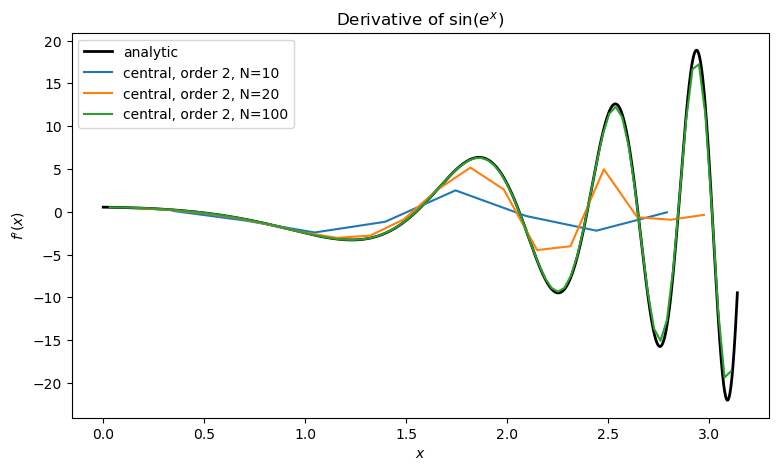

In [4]:
# Test 2: sin(exp(x))
f = lambda x: np.sin(np.exp(x))
df_exact = lambda x: np.cos(np.exp(x)) * np.exp(x)
xx = np.linspace(0, np.pi, 2000)

plt.figure(figsize=(9, 5))
plt.plot(xx, df_exact(xx), 'k', lw=2, label='analytic')
for N in (10, 20, 100):
    dy, X = my_der_calc(f, 0., np.pi, N, 2)
    plt.plot(X, dy, label=f'central, order 2, N={N}')
plt.legend(); plt.xlabel('$x$'); plt.ylabel("$f'(x)$"); plt.title(r"Derivative of $\sin(e^x)$")
plt.show()

### Convergence and round-off error
How does the error depend on the step size $h$? The truncation error is $E\approx Ch^p$, so on a log-log plot we expect a straight line with slope $p$.

1. For $f(x)=\sin x$ on $[0,\pi]$ compute the maximum absolute error
$$E=\max_i\,\big|\cos(X_i)-df_i\big|$$
for both orders (2 and 4) and for many grids, `Ns = np.unique(np.logspace(1, 6.5, 30).astype(int))` (from 10 to about $3\cdot10^6$ points).

2. Plot $E$ against $h=(b-a)/(N-1)$ on a log-log scale (`plt.loglog`), with dashed reference lines $h^2$ and $h^4$.

3. Do the curves have the expected slopes? What happens for very small $h$? Why? Think about what happens when you subtract two almost identical floating point numbers and divide by a tiny $h$.

4. Optional: estimate the experimental order of convergence from consecutive points,
$$p\approx\frac{\log(E_i/E_{i+1})}{\log(h_i/h_{i+1})}.$$

In [ ]:
a, b = 0., np.pi #dot makes an int float
Ns = np.unique(np.logspace(1, 6.5, 30).astype(int)) #creates 30 numbers spaced evenly on a logarithmic scale between 10^1 and 10^6.5
orders = [2, 4]

# Work here
f = np.sin
hs = (b - a) / (Ns - 1)

errors_order2 = []
errors_order4 = []

for N in Ns:
    #order 2
    df2, X2 = my_der_calc(f, a, b, N, order=2)
    err2 = np.max(np.abs(np.cos(X2) - df2))
    errors_order2.append(err2)

    #order 4
    df4, X4 = my_der_calc(f, a, b, N, order=4)
    err4 = np.max(np.abs(np.cos(X4) - df4))
    errors_order4.append(err4)

errors_order2 = np.array(errors_order2)
errors_order4 = np.array(errors_order4)

plt.figure(figsize=(8, 6))
plt.loglog(hs, errors_order2, "o-", label="Order 2")
plt.loglog(hs, errors_order4, "s-", label="Order 4")


TypeError: only integer scalar arrays can be converted to a scalar index

---
## Numerical integration

### Task 2 - Newton-Cotes methods

These methods are useful for functions sampled in equidistant points or measurements with a fixed sampling frequency. 

The trapezoid rule sums up the volume of the trapezoids in each interval, or in other words it approximates the function with a line on each segment:

<img src="https://pythonnumericalmethods.studentorg.berkeley.edu/_images/21.03.1-Trapezoid_integral.png" alt="drawing" width="600"/>

The Simpson's rule approximates the function with a quadratic function for each segment and for that uses three consecutive points.

<img src="https://pythonnumericalmethods.studentorg.berkeley.edu/_images/21.04.1-Simpson_integral.png" alt="drawing" width="600"/>

1. **Implement the trapezoid rule!**
$$
\int_a^b f(x) \text{d}x = \sum_{i=0}^{n-1} h\dfrac{f(x_i)+f(x_{i+1})}{2}
$$
Write the function `my_int(f,a,b,N,method)`, where `f` is a function, `a>b` real numbers defining the integral bounds, `N` is an integer giving the numer of intervals and `method` is a string giving the method to use for the calculation of the integral, in this case `method=trap`.

2. **Implement Simpson's rule!**

The integral of a segment is:
$$
\int_{x_i}^{x_{i+2}} f(x) \text{d}x = \dfrac{h}{3} \left[ f(x_i)+ 4f(x_{i+1})+  f(x_{i+2}) \right]
$$
Take a peace of paper and derive the formula for the whole interval. Implement the formula in your previous `my_int` function with `method=simp`.

3. Simpson’s rule requires an even number of intervals. What happens if `N` is odd, and why is this a limitation?🙋‍♂️
4. Compare the performance of the two methods on 

$$
\int_0^\pi \sin(x) \text{d} x
$$ 

and 

$$
\int_{-1}^{+1} \sqrt{1-x^2} \text{d}x\;.
$$ 

Plot the results of your integral as a function of `N`, start with 100 points and go up to 3000 points with a step size of 10. Also plot the analytic result of the integral as a horizontal line. 

5. Analyze the error, defined as
$$
\text{err}(N) = \left\lvert \int_a^b f(x) \text{d}x - \text{my\_ int(f,a,b,N,method)}\right\lvert\;,
$$
does it follows $\mathcal{O}(h^2)$ and $\mathcal{O}(h^4)$ for the trapezoid and the Simpson method respectively. Conduct the following experiment, compute the integral for up to $N=1000$ points and plot the error with a logaritmic y axis. Can you explein what you see?🙋‍♂️

In [ ]:
def my_int(f,a,b,N,method):
    if(not callable(f)): raise TypeError('f has to be a funtion')
    if(not isinstance(a,float)): raise TypeError('a has to be a float')
    if(not isinstance(b,float)): raise TypeError('b has to be a float')
    if(not isinstance(N,int)): raise TypeError('N has to be an integer')
    if(not isinstance(method,str)): raise TypeError('option has to be a string')
    if(method=='simp'):
        if N % 2 == 1:
            raise ValueError("N must be even for Simpson's rule.")
    # step size
    h = ...
    # array of x values, be careful with the endpoints, check your array!!! 
    x = ...
    y = f(x)
    # Trapezoidal rule formula
    if(method=='trap'):
        integral = ...
    # Simpson's rule formula
    if(method=='simp'):
        integral = ...
    return integral

f1 = lambda x: np.sin(x)
f2 = lambda x: np.sqrt(1-x**2)

print(my_int(f1,0.,np.pi,100,'trap'))
print(my_int(f1,0.,np.pi,100,'simp'))
print(my_int(f2,-1.0,1.0,100,'trap'))
print(my_int(f2,-1.0,1.0,100,'simp'))
print(np.pi/2)


### Task 3 - Gauss-Legendre quadrature
Sometimes you need very accurate integral of known functions. The Gauss-Legendre quadrature with $n$ points integrate polinomials of order $2n-1$ exactly. For that uses a special sampling of points ($x_i$) with special weights ($w_i$).

1. Use scipy to find the nodes and the weights (see the code below with the funtion `roots_legendre`) and then implement the Gauss-Legendre quadrature.
$$
\int_{-1}^{1} f(x) \text{d} x = \sum_{i=1}^n w_i f(x_i)
$$
Use your previous funtion `my_int` with `method=quad` and `N` is the number of points. 

2. To make it a widely applicable method we need to make it work with arbitrary intervals. It can be done with the change of variables.
$$
\int_a^b f(x) \text{d} x = \dfrac{b-a}{2} \sum_{i=1}^n w_i f\left( \dfrac{a+b}{2}+\dfrac{b-a}{2}x_i \right) = \sum_{i=1}^N \tilde{w}_i f(\tilde{x}_i)
$$ 
implement this in your code. Note that it gives the original formula for `a=-1` and `b=1`.

3. Analyze the performance of the method on 

$$
\int_0^\pi \sin(x) \text{d} x$$ 

and 

$$
\int_{-1}^{+1} \sqrt{1-x^2} \text{d}x\;.
$$

Plot the error of the integral as you increase the number of points from $N=4$ up to $N=20$. Also compare with your previous results with trapezoid and Simspon integrals (for that use the earlier range in $N$). 

In [ ]:
from scipy.special import roots_legendre
[xi,wi]=roots_legendre(n=5) # this function gives you the points and the corresponding wights for the quadrature

In [ ]:
# The implementation of the previous my_int function which you should modify to include the quadrature method
def my_int(f,a,b,N,method):
    if(not callable(f)): raise TypeError('f has to be a funtion')
    if(not isinstance(a,float)): raise TypeError('a has to be a float')
    if(not isinstance(b,float)): raise TypeError('b has to be a float')
    if(not isinstance(N,int)): raise TypeError('N has to be an integer')
    if(not isinstance(method,str)): raise TypeError('option has to be a string')
    if(method=='simp'):
        if N % 2 == 1:
            raise ValueError("N must be even for Simpson's rule.")
    if (method=='trap' or method=='simp'):
        h = (b - a) / N  # step size
        x = np.linspace(a, b, N+1)  # N+1 points
        y = f(x)
    # Trapezoidal rule formula
    if(method=='trap'):
        integral = h * (0.5 * y[0] + np.sum(y[1:-1]) + 0.5 * y[-1])
    # Simpson's rule formula
    if(method=='simp'):
        integral = h / 3 * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-2:2]) + y[-1])
    if(method=='quad'):
        #TODO: implement the quadrature method here, you can use the roots_legendre function to get the points and weights
    return integral

### BONUS Task - The volume of an N dimensional hypersphere.

Use Monte Carlo integration to solve the problem. 

1. Generate a large number of points in the $N$ dimensional Euclidean space inside a hyper cube with side length 2 in the $[-1,1]$ interval. You can do it with the `np.uniform` function. 
2. Check that the point is inside the sphere or not.
3. The volume is:
$$
V_{\text{sphere}} = V_{\text{cube}} \dfrac{\text{Number of points inside the sphere}}{\text{Total number of points}} 
$$

The analytic solution for a $d$ dimensional unit sphere:
$$
V_d = \dfrac{\pi^{d/2}}{\Gamma(\frac{d}{2}+\frac{1}{2})} 
$$
where $\Gamma(x)$ is the [Gamma funtion](https://mathworld.wolfram.com/GammaFunction.html).

4. Check the error of your Monte Carlo integral for $d=10$. Use exponentially increasing number of points for the integral up to $N=10^6$ and plot the error with a logarithmic $x$ axis.

<span style="color:red">**The following exercises are not mandatory, but you can use them to practice the skills you learned during the class.**</span>

### Extra practice - Motion of a piston

The crank $AB$ of length $R = 90$ mm is rotating at a constant angular speed of
$\text{d}\theta /\text{d} t  = 5 000$ rev/min. The position of the piston $C$ can be shown to vary with the $\theta$ angle as 
$$
x=R\left( \cos \theta + \sqrt{2.5^2-\sin^2\theta} \right)\;.
$$

Write a program that plots the position, the velocity and the acceleration of the piston between $\theta=0^\circ$ and $180^\circ$ in $1^\circ$ steps.

![piston.png](piston.png)

### Extra practice - Plane velocity based on radar data

The radar stations $A$ and $B$, separated by the distance $a = 500$ m, track the plane $C$ by recording the angles $\alpha$ and $\beta$ at one-second intervals. If three successive readings are

| t(s)           | 9     | 10    | 11    |
|----------------|-------|-------|-------|
| $\alpha$ [deg] | 54.8  | 54.06 | 53.34 |
| $\beta$ [deg]  | 65.59 | 64.59 | 63.62 |

The coordinates of the plane can be shown to be
$$
x=a \dfrac{\tan\beta}{\tan\beta-\tan\alpha} \qquad y=a\dfrac{\tan\alpha\tan\beta}{\tan\beta-\tan\alpha}
$$

1. Calculate the speed $v$ of the plane and the climb angle $\gamma$ at $t = 10$ s.
2. Calculate the acceleration $a$ of the plane and the $\delta$ angle between the acceleration and the horizontal direction.

![alt text](radar.png)

### Extra practice - Electrostatics

There is a rod along the $z$ axis between $-L/2$ and $L/2$. The rod has a uniform $\lambda$ charge density. Calculate the electrostatic potential along the $z$ axis:
$$
V(z) = \dfrac{1}{4\pi\varepsilon_0} \int_{-L/2}^{L/2} \text{d} t \dfrac{\lambda }{\sqrt{t^2+z^2}} 
$$

The analytic solution is:
$$
V(z) = \dfrac{\lambda}{2\pi\varepsilon_0} \text{arsinh}\left( \dfrac{L}{2z} \right)
$$

1. Use your own implementation of one of the methods studied at class (trapezoid, Simpson, Gauss-Legendre) and calculate the integral. Note that you have to do this for different points along the $z$ axis. Define the function `rod_potential(lambda,L,z,N)`, where `lambda` is the charge density, `L` is the length of the rod, `z` is the coordinates where the potential is evaluated and `N` is the number of points used for the integration. Use an interval of $[-5L,5L]$ and $N=100$ for Newton-Cotes methods or $N=10$ for Gauss-Legendre quadrature.
2. Check the convergence of your result by comparing with the analytic result. Plot the error on a 2D heatmap as a function of the number of points used for the integral and the $z$ coordinate. 
3. Generalize your solver to work for any $\lambda(t)$ charge distribution.
4. Calculate the potential for $\lambda(t)=\cos(\pi t/L)$.